In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [9]:
from pathlib import Path

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent 

df = pd.read_csv(project_dir/"data"/ "hour.csv")

df.head(1)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16


In [11]:
df.shape
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

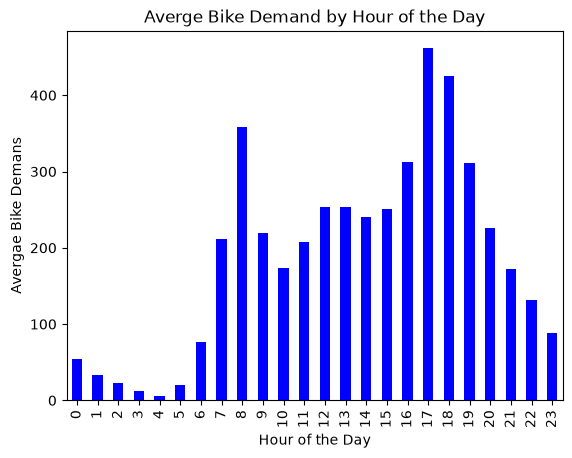

In [ ]:
df.groupby("hr")["cnt"].mean().plot(kind = "bar", color = "blue")

plt.title("Averge Bike Demand by Hour of the Day")

plt.xlabel("Hour of the Day")

plt.ylabel("Avergae Bike Demands")

plt.show()

In [ ]:
hourly_by_day = df.groupby(["weekday", "hr"])["cnt"].mean().reset_index()

hourly_by_day.head()

,weekday,hr,cnt
0,0,0,93.990385
1,0,1,77.432692
2,0,2,61.627451
3,0,3,31.144231
4,0,4,9.362745


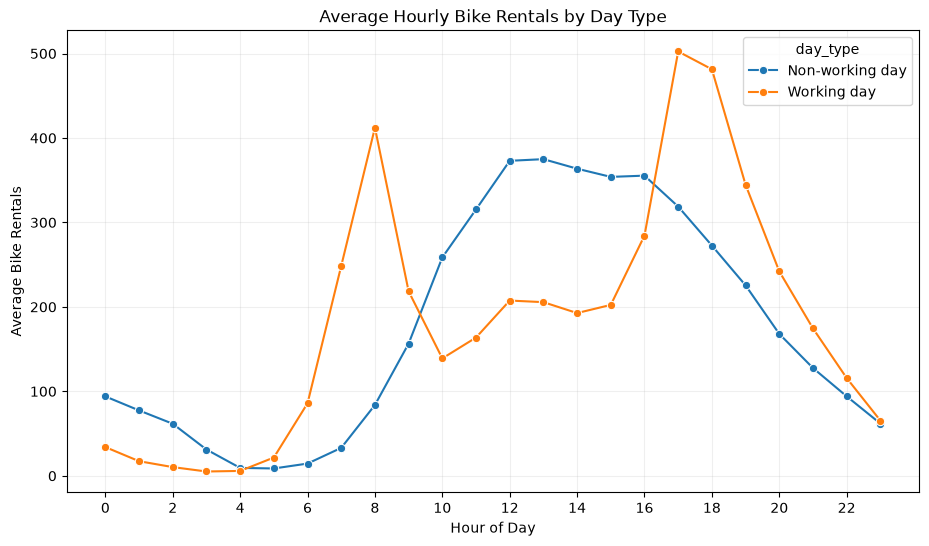

In [27]:
hourly_by_day["day_type"] = (
    hourly_by_day["weekday"]
    .map({0: "Non-working day", 1: "Working day"})
)

plt.figure(figsize=(11, 6))

sns.lineplot(
    data=hourly_by_day,
    x="hr",
    y="cnt",
    hue="day_type",
    marker="o"
)

plt.title("Average Hourly Bike Rentals by Day Type")
plt.xlabel("Hour of Day")
plt.ylabel("Average Bike Rentals")
plt.xticks(np.arange(0, 24, 2))
plt.grid(alpha=0.2)
plt.show()

### Research Question

Do hourly bike rental patterns differ between working and non-working days?

### Findings

The initial analysis revealed two peaks in average hourly bicycle rentals, occurring around 8 AM and 5–6 PM.

After separating observations by working-day status, this pattern remained apparent on working days. However, non-working days exhibited a different pattern, with rental demand peaking around midday (12–1 PM) before gradually declining.

These findings suggest that the relationship between the hour of the day and bicycle rental demand differs depending on whether it is a working or non-working day.

### Possible Explanation

One possible explanation for the morning and evening peaks on working days is commuter behaviour. Individuals may be more likely to rent bicycles when travelling to and from work.

In contrast, the midday peak on non-working days may reflect recreational cycling, as individuals have greater flexibility over when they travel.

The similarity between the aggregate pattern and the working-day pattern could partly reflect the greater number of working days represented in the dataset. However, this explanation requires further examination of group frequencies and rental volumes.

### Limitations

Although the observed patterns are consistent with differences between commuting and recreational cycling, the dataset does not directly identify individuals' reasons for renting bicycles. Therefore, these explanations remain hypotheses rather than established causal relationships.

Other factors, such as temperature, weather conditions, seasonality, and public holidays, may also influence rental demand and contribute to the observed differences.

Furthermore, the dataset represents the Capital Bikeshare system in the Washington, DC area during 2011–2012. Consequently, the findings may not generalise to cities with different transport infrastructure, commuting behaviours, or cycling cultures.